<img src='../../media/common/LogoWekeo_Copernicus_RGB_0.png' align='left' height='96px'></img>


Copyright (c) 2025 European Union

License: MIT


# Download CLMS data with R


Use the WEkEO Harmonised Data Access (HDA) API and the `hdar` R client to access data from the Copernicus Land Monitoring Service (CLMS).

This notebook introduces a reusable workflow for preparing the environment, defining a data request, searching for available files, downloading selected results, and extracting archived data. Adapt the example query to the dataset, area, and time period of interest.


[![Launch WEkEO](https://img.shields.io/badge/launch-WEKEO-1a4696.svg)](https://jupyterhub.prod.wekeo2.eu/)

Open WEkEO JupyterHub, open this notebook from your cloned `wekeo4land` repository, and select the **R** kernel.


**PREREQUISITES**

- A [WEkEO account](https://my.wekeo.eu/user-registration).
- Jupyter with an R kernel, internet access, and permission to install R packages.
- WEkEO credentials configured in `~/.hdarc`; see the authentication section below.
- A local clone of the [wekeo4land repository](https://github.com/wekeo/wekeo4land) with write access and enough space for downloaded and extracted files.


**LEARNING OUTCOMES**

At the end of this notebook you will know how to:

- Prepare an R environment and authenticate with WEkEO.
- Define a data query and inspect search results.
- Download selected files with progress messages.
- Extract ZIP archives and clean up the working folders.


**CONTENTS**

1. [1. Prepare your environment](#1-prepare-your-environment)
2. [2. Search and download data](#2-search-and-download-data)
3. [3. Extract downloaded data](#3-extract-downloaded-data)
4. [4. Cleanup](#4-cleanup)
5. [5. Take home messages](#5-take-home-messages)
6. [6. Next steps](#6-next-steps)
7. [7. Data references](#7-data-references)


<hr>


## 1. Prepare your environment


### Install and load packages


Install missing packages once, then load them before running the workflow. ZIP extraction uses the built-in `utils::unzip()` function.


In [4]:
required_packages <- c("hdar", "jsonlite")

for (pkg in required_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg, repos = "https://cloud.r-project.org")
  }
}

invisible(lapply(required_packages, function(pkg) {
  library(pkg, character.only = TRUE)
}))

### Set working and output directories


Use the root of your cloned `wekeo4land` repository as the working directory. The next cell searches the current directory and its parents for a folder named `wekeo4land`, then falls back to `~/wekeo4land`. Set `repo_root` explicitly if your clone is elsewhere or has another name.

Downloads are stored in `data/download/land` and extracted files in `data/processing/land`, relative to the repository root. Keep generated data out of version control. Cleanup later removes both of these folders, including files from earlier runs.


In [2]:
# Find the repository from the current directory or its parents.
# If your clone has a different name/location, set repo_root explicitly below.
repo_root <- NULL
candidate <- normalizePath(getwd(), winslash = "/", mustWork = TRUE)

repeat {
  if (basename(candidate) == "wekeo4land") {
    repo_root <- candidate
    break
  }
  parent <- dirname(candidate)
  if (identical(parent, candidate)) break
  candidate <- parent
}

# Fallback for notebooks launched outside the repository.
if (is.null(repo_root)) repo_root <- path.expand("~/wekeo4land")
# repo_root <- "/path/to/wekeo4land"  # Uncomment and edit if needed.

if (!dir.exists(repo_root)) {
  stop("Set repo_root to the location of your cloned wekeo4land repository.")
}
repo_root <- normalizePath(repo_root, winslash = "/", mustWork = TRUE)
setwd(repo_root)

# Keep downloaded and extracted data separate from notebook source files.
download_dir_path <- file.path(repo_root, "data", "download", "land")
processing_dir_path <- file.path(repo_root, "data", "processing", "land")

for (path in c(download_dir_path, processing_dir_path)) {
  if (!dir.exists(path)) dir.create(path, recursive = TRUE)
  if (!dir.exists(path)) stop("Cannot create directory: ", path)
}

cat("Repository:", repo_root, "\n")
cat("Download directory:", download_dir_path, "\n")
cat("Extraction directory:", processing_dir_path, "\n")


Repository: /home/jovyan/wekeo4land 
Download directory: /home/jovyan/wekeo4land/data/download/land 
Extraction directory: /home/jovyan/wekeo4land/data/processing/land 


### Authenticate with WEkEO


Configure your WEkEO username and password in `~/.hdarc` before running the next cell. Follow the [WEkEO R client authentication guide](https://help.wekeo.eu/en/articles/7035318-how-to-use-the-hdar-package-for-accessing-the-wekeo-hda-api-in-r) for the required format. Keep credentials outside the notebook.

The client reads the saved credentials automatically.


In [3]:
client <- hdar::Client$new()

<hr>


## 2. Search and download data


### Define the query


Use the [WEkEO Data Viewer](https://wekeo.copernicus.eu/data?view=viewer) to select a dataset and configure the available search filters. Use **Show API request(s)** to obtain a JSON query.

The query below provides a worked example using CLMS Grassland data. Replace it with a request for your chosen product, or adjust its spatial and temporal filters. Query parameters vary by dataset; bounding boxes, where supported, use the order west, south, east, north.


In [5]:
# Query for CLMS Grassland data
query_CLMS <- '{
  "dataset_id": "EO:CLMS:DAT:GRA_10M_YEARLY_2017_PRESENT",
  "bbox": [
    6.350667697456856,
    54.31318755904486,
    13.265810732724411,
    58.25052763024132
  ],
  "startdate": "2024-01-01T00:00:00.000Z",
  "enddate": "2024-12-31T23:59:59.999Z",
  "datasetIdentifier": [
    "clms_vlcc_grassland_europe_10m_yearly_v1"
  ],
  "itemsPerPage": 200,
  "startIndex": 0
}'

### Search and inspect results


Submit the query to retrieve matching files and inspect their identifiers before downloading. Use the search method’s `limit` argument if you want to restrict the number of returned results.


In [6]:
cat("Searching for CLMS Grassland data...\n")
flush.console()
matches <- client$search(query_CLMS)

cat(sprintf("Found %d matching files.\n", length(matches$results)))
if (length(matches$results) > 0L) {
  print(vapply(matches$results, function(x) as.character(x$id), character(1)))
}

Searching for CLMS Grassland data...


Found 28 files

Total Size 100 MB



Found 28 matching files.
 [1] "CLMS_HRLVLCC_GRA_S2024_R10m_E43N38_03035_V01_R00"
 [2] "CLMS_HRLVLCC_GRA_S2024_R10m_E42N35_03035_V01_R00"
 [3] "CLMS_HRLVLCC_GRA_S2024_R10m_E42N37_03035_V01_R00"
 [4] "CLMS_HRLVLCC_GRA_S2024_R10m_E41N39_03035_V01_R00"
 [5] "CLMS_HRLVLCC_GRA_S2024_R10m_E41N34_03035_V01_R00"
 [6] "CLMS_HRLVLCC_GRA_S2024_R10m_E41N38_03035_V01_R00"
 [7] "CLMS_HRLVLCC_GRA_S2024_R10m_E42N38_03035_V01_R00"
 [8] "CLMS_HRLVLCC_GRA_S2024_R10m_E41N36_03035_V01_R00"
 [9] "CLMS_HRLVLCC_GRA_S2024_R10m_E44N35_03035_V01_R00"
[10] "CLMS_HRLVLCC_GRA_S2024_R10m_E43N37_03035_V01_R00"
[11] "CLMS_HRLVLCC_GRA_S2024_R10m_E42N39_03035_V01_R00"
[12] "CLMS_HRLVLCC_GRA_S2024_R10m_E42N34_03035_V01_R00"
[13] "CLMS_HRLVLCC_GRA_S2024_R10m_E43N34_03035_V01_R00"
[14] "CLMS_HRLVLCC_GRA_S2024_R10m_E42N36_03035_V01_R00"
[15] "CLMS_HRLVLCC_GRA_S2024_R10m_E44N34_03035_V01_R00"
[16] "CLMS_HRLVLCC_GRA_S2024_R10m_E44N37_03035_V01_R00"
[17] "CLMS_HRLVLCC_GRA_S2024_R10m_E43N35_03035_V01_R00"
[18] "CLMS_HRLVLCC_GRA_

### Download selected files


Set `max_files` to control how many results to download. The example selects up to five files in the returned order and reports progress for each file. Use `selected_indexes` to choose specific results. Setting `prompt = FALSE` avoids interactive confirmation in Jupyter.


In [9]:
max_files <- 5L
# Choose one selection option (R indexes start at 1).
# Default: first max_files results, or all results if fewer are available.
selected_indexes <- head(seq_along(matches$results), max_files)

# Alternatives: uncomment ONE line to replace the default selection.
# selected_indexes <- 1:5       # First five files (requires at least five matches).
# selected_indexes <- c(2, 4)   # Second and fourth files.
#selected_indexes <- 3L        # Third file only.

# Check that every selected index refers to an available result.
if (length(selected_indexes) > 0L &&
    (anyNA(selected_indexes) ||
     any(!is.finite(selected_indexes)) ||
     any(selected_indexes != floor(selected_indexes)) ||
     any(selected_indexes < 1L | selected_indexes > length(matches$results)))) {
  stop("Select whole-number indexes between 1 and ", length(matches$results), ".")
}

if (length(selected_indexes) == 0L) {
  cat("No matching files to download. Check the query.\n")
} else {
  cat(sprintf("Downloading %d file(s) to %s\n",
              length(selected_indexes), download_dir_path))

  for (i in seq_along(selected_indexes)) {
    index <- selected_indexes[i]
    cat(sprintf("\n[%d/%d] Starting: %s\n",
                i, length(selected_indexes), matches$results[[index]]$id))
    flush.console()

    matches$download(
      output_dir = download_dir_path,
      selected_indexes = index,
      prompt = FALSE
    )

    cat(sprintf("[%d/%d] Download call finished.\n", i, length(selected_indexes)))
    flush.console()
  }

  cat("\nAll selected download calls finished.\n")
}



[1/5] Starting: CLMS_HRLVLCC_GRA_S2024_R10m_E43N38_03035_V01_R00
[1/5] Download call finished.

[2/5] Starting: CLMS_HRLVLCC_GRA_S2024_R10m_E42N35_03035_V01_R00
[2/5] Download call finished.

[3/5] Starting: CLMS_HRLVLCC_GRA_S2024_R10m_E42N37_03035_V01_R00
[3/5] Download call finished.

[4/5] Starting: CLMS_HRLVLCC_GRA_S2024_R10m_E41N39_03035_V01_R00
[4/5] Download call finished.

[5/5] Starting: CLMS_HRLVLCC_GRA_S2024_R10m_E41N34_03035_V01_R00
[5/5] Download call finished.

All selected download calls finished.


<div style="border-left: 5px solid #1E88E5; background-color: #E3F2FD; padding: 12px; border-radius: 4px; margin: 10px 0;"><b>Note:</b> These messages track files, rather than bytes transferred. The download folder may also contain files from earlier runs. Existing-file handling is controlled by the client.</div>


<hr>


## 3. Extract downloaded data


Extract ZIP archives found in the download folder, including archives from earlier runs. Files supplied in other formats remain in the download folder. Extraction can overwrite files with the same names in the processing folder.


In [10]:
# Use R's built-in extractor explicitly; the zip package also exports unzip().
archives <- list.files(download_dir_path, pattern = "\\.zip$",
                       full.names = TRUE, ignore.case = TRUE)
if (length(archives) == 0L) cat("No ZIP archives found; check the downloaded file formats.\n")

for (file_name in archives) {
  size <- file.info(file_name)$size
  if (is.na(size) || size == 0 || file.access(file_name, 4) != 0) {
    stop("Archive is empty or unreadable: ", file_name,
         ". Check the download and file permissions before extracting.")
  }

  cat("Decompressing", basename(file_name), "... ")
  contents <- utils::unzip(file_name, list = TRUE)
  if (nrow(contents) == 0L) {
    stop("Archive is invalid or empty: ", file_name,
         ". Remove this archive and rerun its download cell.")
  }
  extracted <- utils::unzip(file_name, exdir = processing_dir_path)
  if (length(extracted) == 0L || !all(file.exists(extracted))) {
    stop("Extraction incomplete: ", file_name,
         ". Check the archive and available disk space.")
  }
  cat("DONE\n")
}

Decompressing CLMS_HRLVLCC_GRA_S2024_R10m_E41N34_03035_V01_R00.zip ... DONE
Decompressing CLMS_HRLVLCC_GRA_S2024_R10m_E41N39_03035_V01_R00.zip ... DONE
Decompressing CLMS_HRLVLCC_GRA_S2024_R10m_E42N35_03035_V01_R00.zip ... DONE
Decompressing CLMS_HRLVLCC_GRA_S2024_R10m_E42N37_03035_V01_R00.zip ... DONE
Decompressing CLMS_HRLVLCC_GRA_S2024_R10m_E43N38_03035_V01_R00.zip ... DONE


Previewing: /home/jovyan/wekeo4land/data/processing/land/CLMS_HRLVLCC_GRA_S2024_R10m_E41N39_03035_V01_R00/CLMS_HRLVLCC_GRA_S2024_R10m_E41N39_03035_V01_R00.tif 
class       : SpatRaster
size        : 10000, 10000, 1  (nrow, ncol, nlyr)
resolution  : 10, 10  (x, y)
extent      : 4100000, 4200000, 3900000, 4000000  (xmin, xmax, ymin, ymax)
coord. ref. : ETRS89-extended / LAEA Europe (EPSG:3035)
source      : CLMS_HRLVLCC_GRA_S2024_R10m_E41N39_03035_V01_R00.tif
categories  : class_name, area_km2, area_perc, count
name        :          class_name
min value   : all non-grass areas
max value   :        outside area


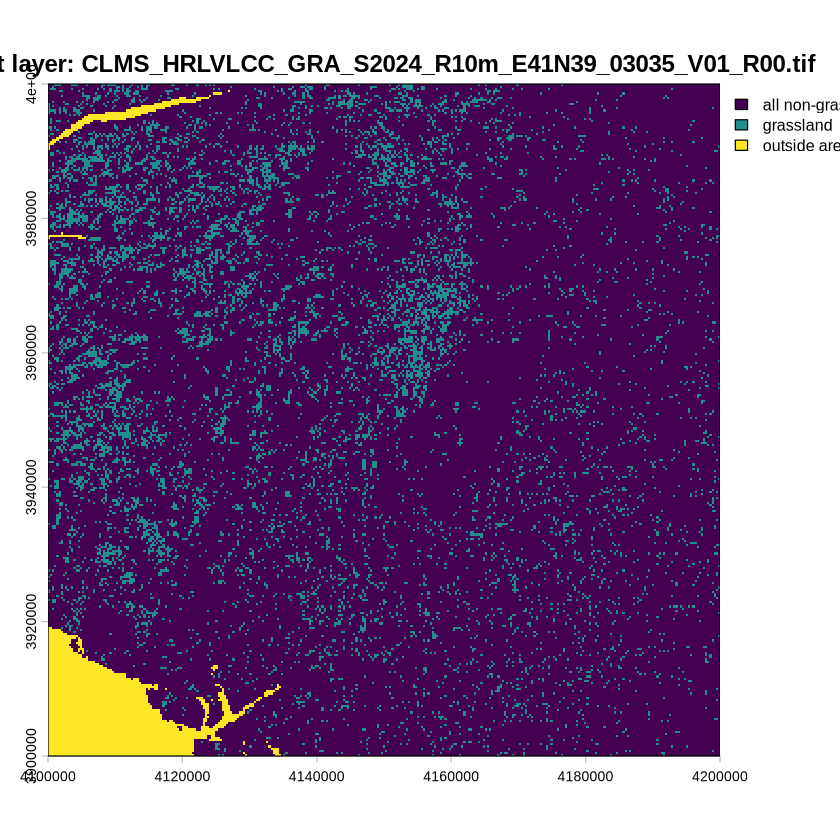

In [17]:
# Look for GeoTIFFs in both output folders, preferring extracted files.
raster_files <- unique(c(
  list.files(processing_dir_path, pattern = "\\.tiff?$",
             recursive = TRUE, full.names = TRUE, ignore.case = TRUE),
  list.files(download_dir_path, pattern = "\\.tiff?$",
             recursive = TRUE, full.names = TRUE, ignore.case = TRUE)
))

if (length(raster_files) == 0L) {
  cat("No GeoTIFF files found. Check the downloaded product's file format.\n")
} else {
  # Change this index to preview another available GeoTIFF.
  preview_file <- raster_files[2L]
  cat("Previewing:", preview_file, "\n")
  raster_data <- terra::rast(preview_file)
  print(raster_data)

  terra::plot(raster_data[[1L]],
       main = paste("First layer:", basename(preview_file)),
       maxcell = 100000)
}

<hr>


## 4. Cleanup


<div style="border-left: 5px solid #FB8C00; background-color: #FFF3E0; padding: 12px; border-radius: 4px; margin: 10px 0;"><b>Warning:</b> Running the next cell deletes both output folders and all their contents, including files from previous runs. Running all cells also performs this cleanup.</div>


In [ ]:
for (path in c(download_dir_path, processing_dir_path)) {
  if (dir.exists(path)) {
    status <- unlink(path, recursive = TRUE)
    if (status != 0L || dir.exists(path)) stop("Could not remove: ", path)
  }
}
cat("Cleanup complete. Downloaded and extracted files removed.\n")


## 5. Take home messages


- The HDA client uses a JSON query to identify matching CLMS files.
- `limit` restricts search results; `selected_indexes` selects files for download.
- The download count is configurable and progress is reported for each file.
- Downloads and extracted files are kept in separate folders; cleanup removes both folders at the end.


## 6. Next steps


Adapt the query to another CLMS product, area, or time period, and adjust the download count as needed. Consult the product documentation to understand the file format and available variables before continuing with analysis or visualisation.


## 7. Data references


Consult the [WEkEO Data Viewer](https://wekeo.copernicus.eu/data?view=viewer) and the [CLMS portal](https://land.copernicus.eu/) for dataset descriptions, usage conditions, and citation guidance. When citing downloaded data, record the product name, version, provider, and access date.

The supplied example query selects the following product:

- Dataset ID: `EO:CLMS:DAT:GRA_10M_YEARLY_2017_PRESENT`
- Dataset identifier: `clms_vlcc_grassland_europe_10m_yearly_v1`

Update these references when using a different dataset.


<hr>


[View on GitHub](https://github.com/wekeo) | [Visit WEkEO](https://wekeo.copernicus.eu) | [Run notebooks on the WEkEO Workspace](https://jupyterhub.prod.wekeo2.eu/) | [Contact helpdesk for support](mailto:support@wekeo.eu)
